In [ ]:
import os

os.environ.setdefault("PYRITE_MC_BACKEND", "cpu")
import marimo as mo  # noqa: F401
import matplotlib.pyplot as plt
import numpy as np

import pyrite

_ = pyrite.fetch_tables()
tables_ready = True

# Classical radiation at MeV beam energies

[![Open in Molab](https://marimo.io/molab-shield.svg)](https://molab.marimo.io/github/Quantum-Light-Matter-Cooperative-QLMC/pyrite/blob/main/docs/notebooks/16-classical-mev-radiation.py)

Compare **3, 10 and 30 MeV** electrons crossing **100 nm silicon**, looking
near the beam (**2°**) and backward (**150°**). Plot PXR/CBS, bremsstrahlung
and opt-in transition radiation (TR), then integrate the same **1–3 keV**
photon band at every beam energy. The angles are measured from the incident
beam, not the tilted surface normal.

Open this source locally with
`uv run marimo edit docs/notebooks/16-classical-mev-radiation.py`, or use
Molab's inline environment. The first cell installs missing pinned reference
tables, including BremsLib; later runs reuse them. Six small CPU simulations
use seed **775** and **256 histories per component population**. Compilation
and first-time table downloads can dominate runtime. These histories are
Monte Carlo samples, not a physical bunch or an acquired detector count.

In [ ]:
from pyrite import simulate
from pyrite.beams import Beam, PointBunch, PointSpot
from pyrite.config import CxrReflections, FixedSampling, Numerics, Physics
from pyrite.detectors import Detector, EnergyBins
from pyrite.geometry import Footprint, Slab
from pyrite.units import ureg

energies_MeV = np.array([3.0, 10.0, 30.0])
angles_deg = (2.0, 150.0)
# Shared explicit nodes: no addition or integration across mismatched grids.
photon_energy_eV = np.arange(1_000.0, 3_001.0, 1.0)
target = Slab(
    "silicon",
    thickness=100 * ureg.nm,
    tilt=5 * ureg.degree,
    footprint=Footprint(width=5 * ureg.mm, height=5 * ureg.mm),
)
physics = Physics(
    transition_radiation="history",
    bremsstrahlung_model="bremslib",
    radiative_model="bremslib-soft-hard",
)
numerics = Numerics(
    sampling=FixedSampling(cxr_electrons=256, brem_electrons=256),
    cxr_reflections=CxrReflections(n_families=1),
    energy_model="midpoint",
    energy_bins=(
        EnergyBins()
        .with_cxr_energies(photon_energy_eV * ureg.eV)
        .with_brem_energies(photon_energy_eV * ureg.eV)
    ),
    seed=775,
)

## Keep the MeV source model explicit

`bremsstrahlung_model="bremslib"` requires the directional tables; missing
tables fail with an installation instruction. The default `"auto"` can warn
and fall back to EEDL, which would change this comparison. Coupled radiative
loss includes the staged electron–electron contribution and dielectric
suppression. `transition_radiation="history"` adds the interfering interface
fields within each history; histories add incoherently. No bunch coherence
or quantum channeling is selected.

The 1 eV photon spacing resolves the thin film's backward TR fringes. The
limited reflection family and small history count make this an illustration,
not a converged line-yield calculation. Silicon characteristic K radiation
also lies in this band; it is a separate component, omitted from these plots.

In [ ]:
assert tables_ready
runs = {}
for _energy in energies_MeV:
    for _angle in angles_deg:
        runs[(_energy, _angle)] = simulate(
            Beam(
                kinetic_energy=_energy * ureg.MeV,
                transverse=PointSpot(),
                longitudinal=PointBunch(),
            ),
            target,
            Detector(observation_angle=_angle * ureg.degree),
            physics=physics,
            numerics=numerics,
        )

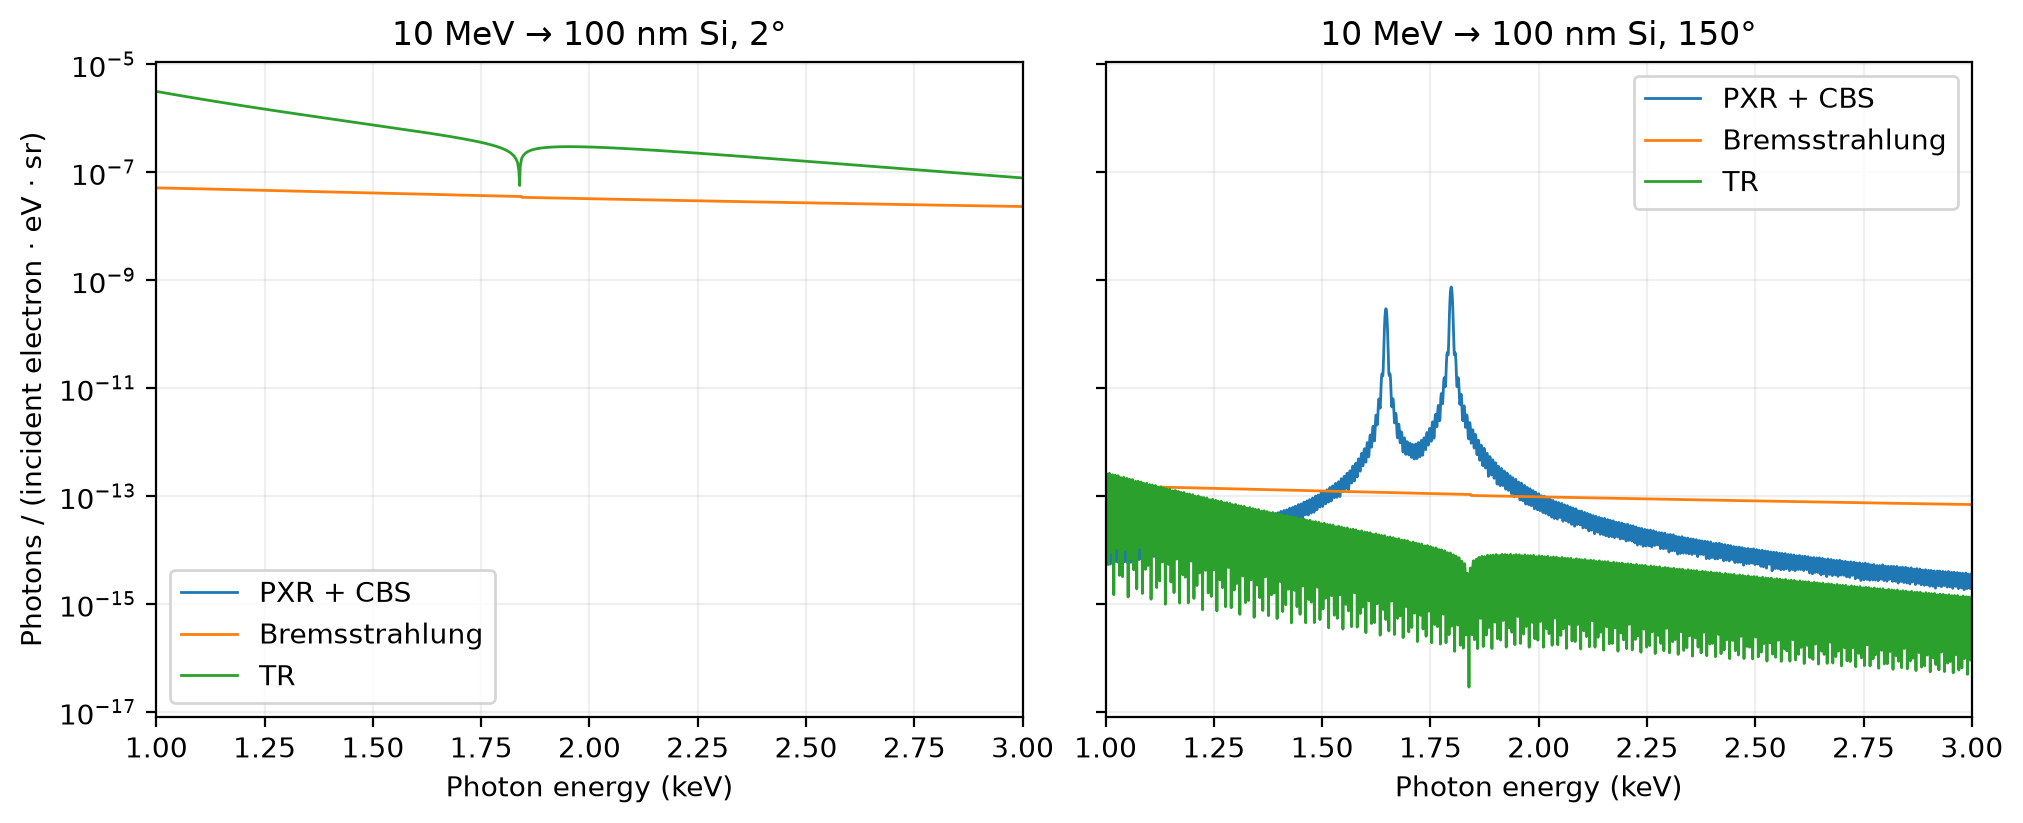

In [ ]:
components = {
    "PXR + CBS": lambda result: result.cxr.incoherent,
    "Bremsstrahlung": lambda result: result.brem,
    "TR": lambda result: result.transition,
}
fig_spectra, _axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained", sharey=True)
for _ax, _angle in zip(_axes, angles_deg, strict=True):
    _result = runs[(10.0, _angle)]
    for _name, _get in components.items():
        _spectrum = _get(_result)
        # Log axes cannot display physical zeros; retain them for integration.
        _ax.plot(
            _spectrum.photon_energy_eV / 1_000,
            np.where(_spectrum.density > 0, _spectrum.density, np.nan),
            label=_name,
            lw=1,
        )
    _ax.set(
        title=f"10 MeV → 100 nm Si, {_angle:g}°",
        xlabel="Photon energy (keV)",
        yscale="log",
        xlim=(1, 3),
    )
    _ax.legend()
    _ax.grid(alpha=0.2)
_axes[0].set_ylabel("Photons / (incident electron · eV · sr)")
fig_spectra  # noqa: B018

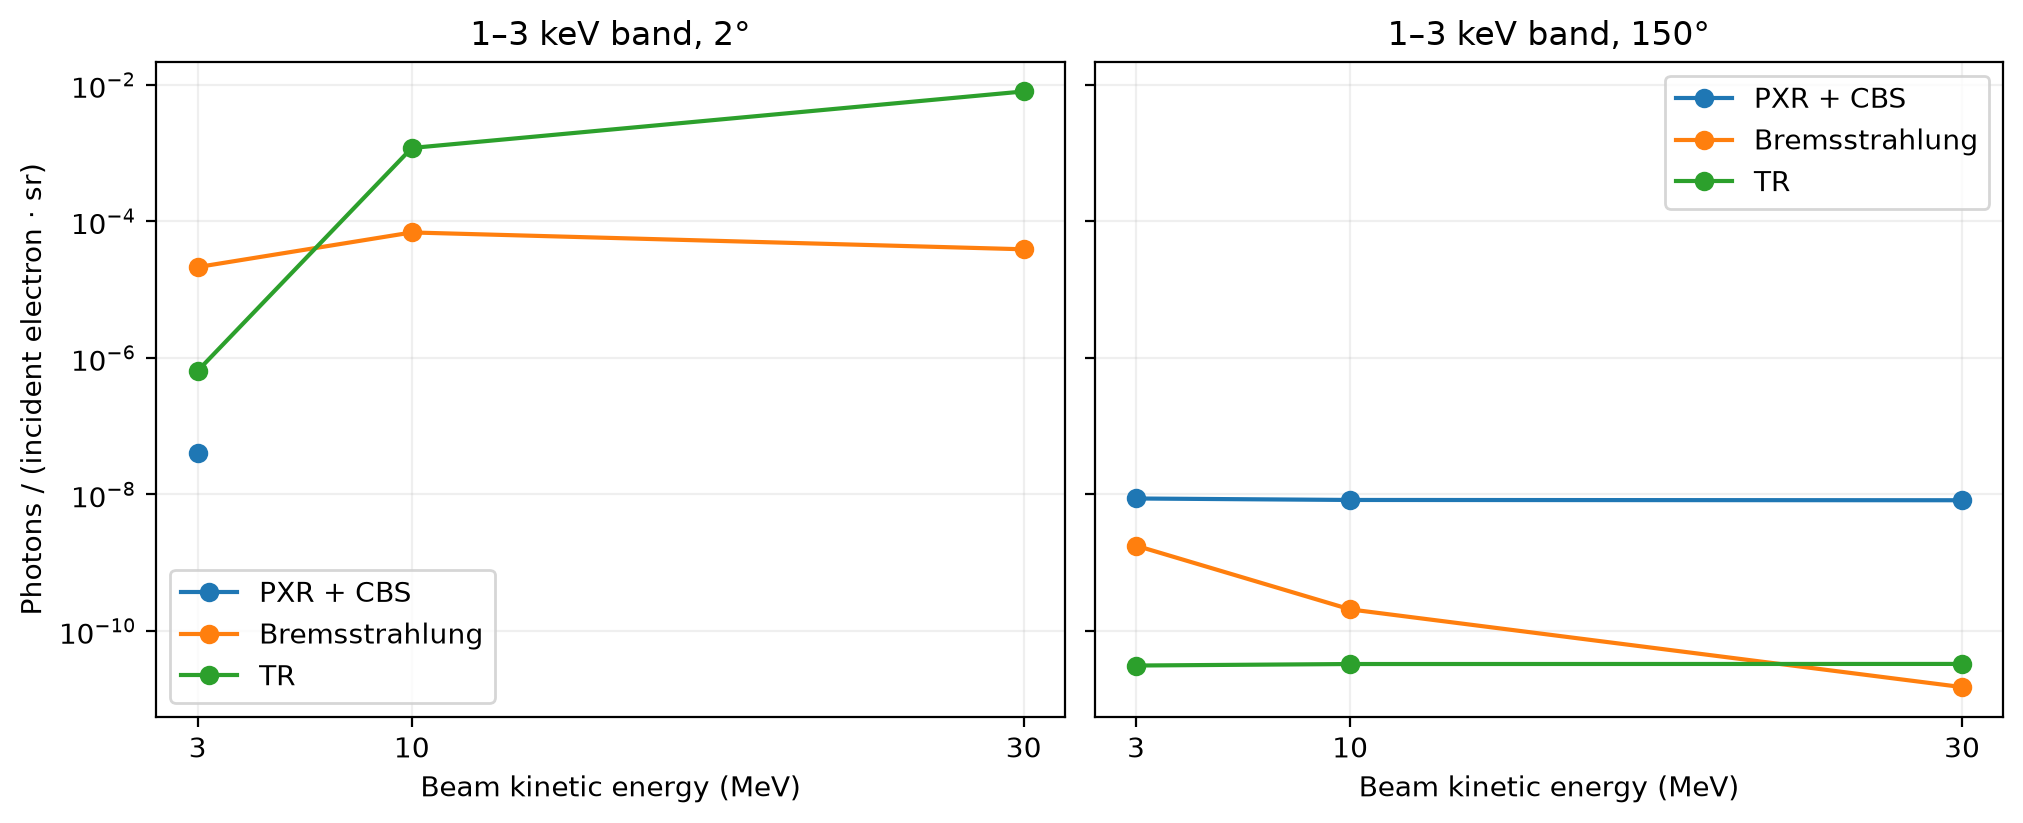

In [ ]:
# All three node-sampled spectra cover exactly 1–3 keV; integrate in eV.
band_yields = {
    (_energy, _angle, _name): float(
        np.trapezoid(
            _get(runs[(_energy, _angle)]).density,
            _get(runs[(_energy, _angle)]).photon_energy_eV,
        )
    )
    for _energy in energies_MeV
    for _angle in angles_deg
    for _name, _get in components.items()
}
fig_yield, _axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained", sharey=True)
for _ax, _angle in zip(_axes, angles_deg, strict=True):
    for _name in components:
        _ax.plot(
            energies_MeV,
            # Exact zeros (no PXR/CBS in this band and direction) leave a gap.
            [band_yields[(_energy, _angle, _name)] or np.nan for _energy in energies_MeV],
            "o-",
            label=_name,
        )
    _ax.set(title=f"1–3 keV band, {_angle:g}°", xlabel="Beam kinetic energy (MeV)", yscale="log")
    _ax.set_xticks(energies_MeV)
    _ax.legend()
    _ax.grid(alpha=0.2)
_axes[0].set_ylabel("Photons / (incident electron · sr)")
fig_yield  # noqa: B018

## Read the comparison within its validity tier

Relativistic bremsstrahlung is concentrated in a cone of half-angle about
$1/\gamma$ around the electron direction: roughly 8.3°, 2.8° and 1.0° at 3,
10 and 30 MeV. A fixed 2° detector therefore sits inside the cone at the two
lower energies but outside it at 30 MeV, so the forward band yield need not
grow with beam energy, while the 150° yield falls steadily. At 2°, TR exceeds
the bremsstrahlung continuum by one to two orders of magnitude at 10 and
30 MeV, so omitting it is an observable-dependent approximation. The notch
near 1.84 keV is the silicon K absorption edge acting on the film's
dielectric response and photon escape.

PXR/CBS is direction selective. Its backward lines barely change between 3
and 30 MeV here, and the forward band holds no PXR/CBS at 10 or 30 MeV
(gaps in the plot). That does not establish its absence at other angles or
photon energies.

All plotted beams fall within the **1–30 MeV** tier of the
[capabilities table](https://pyrite.readthedocs.io/en/latest/physics/capabilities.html#beam-energy-validity).
Its transport comparison uses **W 100 µm / Si 1 mm at 3, 10 and 30 MeV**;
this much thinner film is an illustration, not another independent benchmark.
The evidence is not human signed-off. See the
[MeV full-track validation](https://pyrite.readthedocs.io/en/latest/validation/beam-transport/mev-full-track-transport.html)
for observable-specific gates, including limits on soft-photon counts.

Photons have straight-ray attenuation, not general scattering transport;
thick targets above **0.05 radiation lengths** trigger a warning. This
100 nm Si film is well below that boundary. TR assumes flat interfaces and
a local isotropic dielectric response; the X-ray data used here do not
establish optical/IR validity. The 30–100 MeV extension has additional
limitations, and **>100 MeV is outside this tutorial's supported tier**.
Neither high-energy line coupling nor quantum channeling is tested here.

Try doubling both history counts and halving the photon spacing before
interpreting small differences. Then change 2° to 5° to see how a fixed
observation direction samples the forward cone. Keep the photon band fixed
when comparing yields; no angular acceptance, detector response or beam
current has been applied.

Continue with the
[bremsstrahlung model](https://pyrite.readthedocs.io/en/latest/physics/radiation-physics/bremsstrahlung.html),
[TR physics and omission decisions](https://pyrite.readthedocs.io/en/latest/physics/radiation-physics/transition-radiation.html#decisions),
and the [thin-film TR/CTR tutorial](https://pyrite.readthedocs.io/en/latest/notebooks/specialized/10-transition-radiation.html).

## Continue learning

- [Beam-energy validity tiers](../../physics/capabilities.md#beam-energy-validity)
- [Bremsstrahlung](../../physics/radiation-physics/bremsstrahlung.md)
- [Transition radiation](../../physics/radiation-physics/transition-radiation.md)
- [MeV transport evidence](../../validation/beam-transport/mev-full-track-transport.md)

{download}`Download canonical Marimo notebook <../16-classical-mev-radiation.py>`